In [ ]:
import awkward as ak
import numba
import numpy as np
import pandas as pd
import awkward as ak
import vector
import torch
from scipy.special import softmax
vector.register_numba()
vector.register_awkward()
import os
from copy import deepcopy

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import mplhep as hep
hep.style.use(hep.style.ROOT)

import numba

import seaborn as sns

from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
from sklearn.base import BaseEstimator, TransformerMixin

: 

In [2]:
dctr_input = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/ttHbb_export/training_5wps_multiplewp/no_triggerSF/semilep_channel/dctr_inputs/dctr_datasets/dctr_input_5j3b_1L_test_allyears.parquet"
spanet_model = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/ttHbb_export/training_5wps_multiplewp/no_triggerSF/semilep_channel/spanet_v0_1Lchannel.onnx"
save_folder = "/eos/home-g/gbonomel/projects/www/spanet/1L_channel/spanet_v0_noTriggerSFs/control_regions"

# ensure save folder exists
os.makedirs(save_folder, exist_ok=True)

CMAP_10 = [
    "#3f90da",
    "#ffa90e",
    "#bd1f01",
    "#94a4a2",
    "#832db6",
    "#a96b59",
    "#e76300",
    "#b9ac70",
    "#717581",
    "#92dadd",
]

COLOR_ALIASES = {
    "CMS_blue": CMAP_10[0],        # Blue
    "CMS_orange": CMAP_10[1],      # Orange
    "CMS_red": CMAP_10[2],         # Red
    "CMS_gray": CMAP_10[3],        # Gray
    "CMS_purple": CMAP_10[4],      # Purple
    "CMS_brown": CMAP_10[5],       # Brown
    "CMS_dark_orange": CMAP_10[6], # Dark Orange
    "CMS_beige": CMAP_10[7],       # Beige
    "CMS_dark_gray": CMAP_10[8],   # Dark Gray
    "CMS_light_blue": CMAP_10[9]   # Light Blue
}

colors = {
    "tthbb": COLOR_ALIASES["CMS_red"],
    "ttbb": COLOR_ALIASES["CMS_dark_orange"],
    "ttcc": COLOR_ALIASES["CMS_orange"],
    "ttlf": COLOR_ALIASES["CMS_blue"],
    "ttv": COLOR_ALIASES["CMS_brown"],
    "singletop": COLOR_ALIASES["CMS_purple"],
    "tthcc": COLOR_ALIASES["CMS_light_blue"],
}

labels = {
    "tthbb": 1,
    "ttbb": 2,
    "ttcc": 3,
    "ttlf": 4,
    #"ttv": 5,
    #"singletop": 6,
    #"tth_nonbb": 7,
}

labels_to_plot = {
    "tthbb": 1, 
    "ttbb": 2,
    "ttcc": 3,
    "ttlf": 4,
}

labels_legend = {
    "tthbb": r"$t\bar{t}$Hbb",
    "ttbb": r"$t\bar{t}b\bar{b}$",
    "ttcc": r"$t\bar{t}c\bar{c}$",
    "ttlf": r"$t\bar{t}$lf",
    "ttv": r"$t\bar{t}$V",
    "singletop": "Single top",
    "tth_nonbb": r"$t\bar{t}$Hnon-bb",
    "ttcc_vs_ttlf" : "ttcc_vs_ttlf",
    "tthbb_vs_ttbb": "tthbb_vs_ttbb",
    "tthbb_vs_bkg": "tthbb_vs_bkg",
}

In [32]:
def plot_score(pred_label, score, label, ax, weights=None, title=None, mask=None, log=False, ylim=None, density=False, legend=True):
    if mask is not None:
        pred_label = pred_label[mask]
        if weights is not None:
            weights = weights[mask]
    color = colors.get(label, ax._get_lines.get_next_color())
    n, bins, patches = ax.hist(pred_label, bins=50, range=(0,1),
                               weights=weights, histtype="step",
                               linewidth=2, color=color, label=labels_legend.get(label), density=density)
    if legend:
        ax.legend(fontsize=15)
    ax.set_xlabel(f"{labels_legend.get(score)} SPANet score")
    ax.set_ylabel("A.U." if density else "Counts")
    if log:
        ax.set_yscale("log")
    if ylim is not None:
        ax.set_ylim(*ylim)
    if title:
        ax.set_title(title)
    return n, bins, patches


def plot_scores(true_labels, pred_labels, plot_dir=None, weights=None, title=None, mask=None, log=False, ylim=None, density=False):
    score_names = list(pred_labels.keys())
    n_scores = len(score_names)
    n_cols = 3 if n_scores > 3 else n_scores
    n_rows = int(np.ceil(n_scores / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=[24,14], dpi=100)#figsize=[7 * n_cols, 5 * n_rows], dpi=100)
    axes = np.atleast_2d(axes)
    for i, score in enumerate(score_names):
        ax = axes[i // n_cols][i % n_cols]
        for label in true_labels:
            mask_by_sample = true_labels[label]
            if mask is not None:
                mask_by_sample &= mask
            plot_score(pred_labels[score], score, label, ax=ax,
                       mask=mask_by_sample, weights=weights,
                       title=title, log=log, ylim=ylim, density=density)

    for j in range(n_scores, n_rows * n_cols):
        axes[j // n_cols][j % n_cols].axis("off")

    fig.tight_layout(pad=1.5)
    if plot_dir:
        filename = os.path.join(plot_dir, "classification_scores.png")
        if weights is not None:
            filename = filename.replace(".png","_weighted.png")
        if log:
            filename = filename.replace(".png","_log.png")
        if density:
            filename = filename.replace(".png","_normalised.png")
        plt.savefig(filename, dpi=300)
    plt.show()

In [4]:
def plot_cumulative_significance(true_scores, scores, weights, signal_index=None, bins=30, range=(0, 1), xlabel="Threshold", ylabel="$S/\\sqrt{B}$", plot_dir=None):
    """
    Plots the significance (S/sqrt(B)) as a function of score or any other variable.
        true_score (np.ndarray): True class labels of shape (N,).
        out_score (np.ndarray): Array of classifier outputs with shape (N, num_classes).
        weights (np.ndarray): Event weights of shape (N,).
        signal_class (int): Class label to consider as signal (default=1).
        output_path (str, optional): Path to save the figure. If None, it will not save.
    """

    if signal_index is None:
        signal_index = 1

    class_index = scores.shape[1]

    # save true scores for signal and background
    true_signal = (true_scores == signal_index)
    true_bkg = ~true_signal
    pred_sig_scores = scores[:,signal_index]

    # save the output score for the signal events that are predicted as signal 
    pred_scores = np.argmax(scores, axis=1)
    is_signal_pred = (pred_scores == signal_index)
    score_pred_signal = scores[is_signal_pred,signal_index]

    true_scores_selected = true_scores[is_signal_pred]
    weights_selected = weights[is_signal_pred]

    # cumulative significance vs threshold
    thresholds = np.linspace(0, 1, 100)
    cum_significance_pred = np.zeros_like(thresholds, dtype=float)
    cum_significance_true = np.zeros_like(thresholds, dtype=float)
    
    for i, thr in enumerate(thresholds):
        pass_signal = score_pred_signal > thr
        pass_true_signal = (pred_signale > thr) & true_signal
        pass_true_bkg = (pred_signal > thr) & true_bkg

        S_true_cum = np.sum(weights[pass_true_signal])
        B_true_cum = np.sum(weights[pass_true_bkg])
        cum_significance_true[i] = S_true_cum / np.sqrt(B_true_cum) if B_true_cum > 0 else 0
        
        S_pred_cum = np.sum(weights_selected[pass_signal & (true_scores_selected == 1)])
        B_pred_cum = np.sum(weights_selected[pass_signal & (true_scores_selected != 1)])
        cum_significance_pred[i] = S_pred_cum / np.sqrt(B_pred_cum) if B_pred_cum > 0 else 0  
    
    fig, ax = plt.subplots(figsize=[10,8])
    ax.plot(thresholds, cum_significance_pred, marker='o', color=CMAP_10[0], linestyle='-', label="Predicted as ttHbb")
    ax.plot(thresholds, cum_significance_true, marker='o', color=CMAP_10[1], linestyle='-', label="ttHbb node")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title("Cumulative Significance")
    ax.legend(fontsize=15)

    if plot_dir is not None:
        filename = os.path.join(plot_dir, "cumulative_significance.png")
        plt.savefig(filename, dpi=300)
    plt.show()

In [5]:
class WeightedQuantileTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, n_quantiles=1000, output_distribution='normal'):
        self.n_quantiles = n_quantiles
        self.output_distribution = output_distribution

    def save(self, filename):
        np.savez(
            filename,
            quantiles=self.quantiles_,
            reference_quantiles=self.reference_quantiles_,
            n_quantiles=self.n_quantiles,
            output_distribution=self.output_distribution,
        )

    def load(self, filename):
        data = np.load(filename)
        self.quantiles_ = data["quantiles"]
        self.reference_quantiles_ = data["reference_quantiles"]
        self.n_quantiles = int(data["n_quantiles"])
        self.output_distribution = str(data["output_distribution"])
    
    def _weighted_quantiles(self, X, weights):
        # Calculate weighted quantiles
        sorted_indices = np.argsort(X)
        X_sorted = X[sorted_indices]
        weights_sorted = weights[sorted_indices]
        cum_weights = np.cumsum(weights_sorted) / np.sum(weights_sorted)
        
        # Interpolate to get quantiles
        quantiles = np.interp(np.linspace(0, 1, self.n_quantiles), cum_weights, X_sorted)
        return quantiles
    
    def fit(self, X, y=None, sample_weight=None):
        if sample_weight is None:
            raise ValueError("Sample weights must be provided.")
        
        self.quantiles_ = self._weighted_quantiles(X, sample_weight)
        
        if self.output_distribution == 'normal':
            self.reference_quantiles_ = norm.ppf(np.linspace(0, 1, self.n_quantiles))
        elif self.output_distribution == 'uniform':
            self.reference_quantiles_ = np.linspace(0, 1, self.n_quantiles)
        else:
            raise ValueError(f"Unknown output distribution '{self.output_distribution}'.")
        
        return self
    
    def transform(self, X):
        # Interpolate based on weighted quantiles
        transformed_X = np.interp(X, self.quantiles_, self.reference_quantiles_)
        return transformed_X

Load the scores after inference (that was ran with PocketCoffea) and the dctr variables by loading the parquet file that was processed through `ttbb-DCTR/scripts/create_dctr_datasets_spanet_run3.sh`

In [6]:
# load dctr input from parquet file
df = ak.from_parquet(dctr_input)

In [7]:
df.fields

['JetGood',
 'LeptonGood',
 'PuppiMET',
 'events',
 'spanet_output',
 'tthbb',
 'tthnonbb',
 'ttbb',
 'ttcc',
 'ttlf',
 'singletop',
 'ttv',
 'vjets',
 'data',
 'dctr',
 'metadata',
 'BJetGood',
 'event']

In [8]:
df.event.weight

<Array [0.0191, -0.0555, ... -0.068, -0.00014] type='4464520 * float64'>

In [9]:
df.ttbb

<Array [1, 0, 0, 1, 0, 1, ... 0, 0, 0, 0, 0, 0] type='4464520 * int64'>

In [10]:
np.sum(df.event.weight[df.ttbb] )

-3521.6790010724703

In [11]:
# extract weights by event
weights = df.event.weight
# now construct the event weight starting from weights but changing sign for all events but ttB
event_weights = ak.where(df.ttbb, weights, -weights)

In [12]:
event_weights

<Array [0.0191, 0.0555, ... 0.068, 0.00014] type='4464520 * float64'>

In [13]:
df.spanet_output.fields

['tthbb', 'ttbb', 'ttcc', 'ttlf', 'ttv', 'singletop', 'tth_nonbb']

In [14]:
# true labels from dctr input to use as mask by sample
true_labels = {}
pred_labels = {}
for label in labels_to_plot:
    true_labels[label] = ak.to_numpy(df[f"{label}"]).astype(bool)
    pred_labels[label] = ak.to_numpy(df.spanet_output[f"{label}"])
true_labels
pred_labels

{'tthbb': array([0.12724479, 0.07749162, 0.03744168, ..., 0.04535638, 0.07279955,
        0.10995973], dtype=float32),
 'ttbb': array([0.3078034 , 0.18070893, 0.05992511, ..., 0.070914  , 0.09111445,
        0.04099764], dtype=float32),
 'ttcc': array([0.06291658, 0.13478313, 0.20149387, ..., 0.2557925 , 0.23267119,
        0.05840711], dtype=float32),
 'ttlf': array([0.01615734, 0.09445731, 0.23631965, ..., 0.24907131, 0.14097603,
        0.02410844], dtype=float32)}

In [15]:
pred_labels["tthbb"].shape

(4464520,)

In [16]:
is_tthbb = true_labels["tthbb"]
score_tthbb = ak.to_numpy(pred_labels["tthbb"][is_tthbb])
weights_tthbb = ak.to_numpy(weights[is_tthbb])
pred_labels_transformed = deepcopy(pred_labels)
transformer = WeightedQuantileTransformer(n_quantiles=10000, output_distribution='uniform')
transformer.fit(score_tthbb, sample_weight=weights_tthbb)
transformer.save(f"{save_folder}/tthbb_quantile_transformer.npz")
pred_labels_transformed["tthbb"] = ak.to_numpy(transformer.transform(pred_labels["tthbb"]))

Text(0, 1, 'Counts')

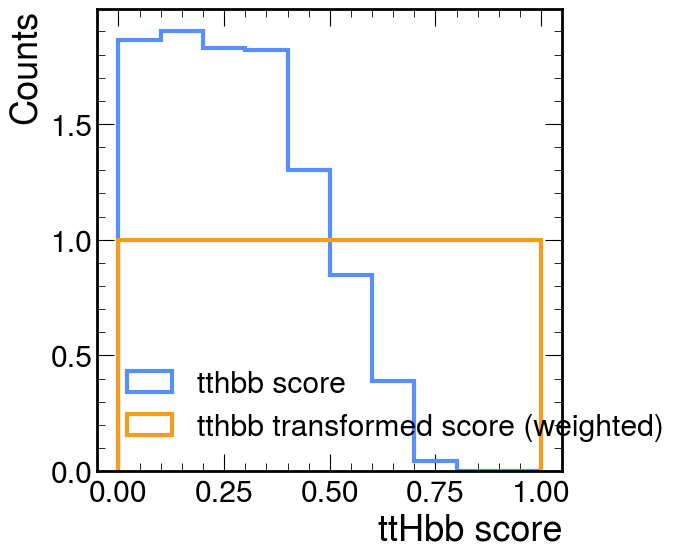

In [17]:
fig, ax = plt.subplots(1,1, figsize=[6,6])
ax.hist(pred_labels["tthbb"][is_tthbb], weights=weights[is_tthbb], bins=10, range=(0,1), histtype="step", linewidth=3, label="tthbb score", density=True)
ax.hist(pred_labels_transformed["tthbb"][is_tthbb], weights=weights[is_tthbb], bins=10, range=(0,1), histtype="step", linewidth=3, label="tthbb transformed score (weighted)", density=True)
ax.legend(loc='best');
ax.set_xlabel("ttHbb score")
ax.set_ylabel("Counts")

In [18]:
pred_labels_transformed

{'tthbb': array([0.24557298, 0.13195012, 0.03622675, ..., 0.0527799 , 0.11997021,
        0.20906246]),
 'ttbb': array([0.3078034 , 0.18070893, 0.05992511, ..., 0.070914  , 0.09111445,
        0.04099764], dtype=float32),
 'ttcc': array([0.06291658, 0.13478313, 0.20149387, ..., 0.2557925 , 0.23267119,
        0.05840711], dtype=float32),
 'ttlf': array([0.01615734, 0.09445731, 0.23631965, ..., 0.24907131, 0.14097603,
        0.02410844], dtype=float32)}

In [19]:
df.spanet_output.fields

['tthbb', 'ttbb', 'ttcc', 'ttlf', 'ttv', 'singletop', 'tth_nonbb']

In [20]:
# discriminate between ttcc (1) and ttllf (0)
spanet_output_ttcc_vs_ttlf = df.spanet_output.ttcc / (df.spanet_output.ttlf + df.spanet_output.ttcc)
#spanet_output_tthbb_vs_ttbb = df.spanet_output.tthbb / (df.spanet_output.tthbb + df.spanet_output.ttbb)
spanet_output_tthbb_vs_bkg = df.spanet_output.tthbb / (df.spanet_output.tthbb + df.spanet_output.ttbb + df.spanet_output.ttcc + df.spanet_output.ttlf)
# add spanet_output_ttcc_vs_ttlf to df.spanet_output fields
df.spanet_output = ak.with_field(df.spanet_output, spanet_output_ttcc_vs_ttlf, "ttcc_vs_ttlf")
#df.spanet_output = ak.with_field(df.spanet_output, spanet_output_tthbb_vs_ttbb, "tthbb_vs_ttbb")
df.spanet_output = ak.with_field(df.spanet_output, spanet_output_tthbb_vs_bkg, "tthbb_vs_bkg")

In [21]:
df.spanet_output.fields

['tthbb',
 'ttbb',
 'ttcc',
 'ttlf',
 'ttv',
 'singletop',
 'tth_nonbb',
 'ttcc_vs_ttlf',
 'tthbb_vs_bkg']

In [22]:
# true labels from dctr input to use as mask by sample
new_labels = list(labels.keys()) 
neyman_var = ["ttcc_vs_ttlf", "tthbb_vs_bkg"]
new_labels.extend(neyman_var)
new_labels

['tthbb', 'ttbb', 'ttcc', 'ttlf', 'ttcc_vs_ttlf', 'tthbb_vs_bkg']

In [23]:
pred_labels_new = {}
for label in new_labels:
    pred_labels_new[label] = ak.to_numpy(df.spanet_output[f"{label}"])
pred_labels_new

{'tthbb': array([0.12724479, 0.07749162, 0.03744168, ..., 0.04535638, 0.07279955,
        0.10995973], dtype=float32),
 'ttbb': array([0.3078034 , 0.18070893, 0.05992511, ..., 0.070914  , 0.09111445,
        0.04099764], dtype=float32),
 'ttcc': array([0.06291658, 0.13478313, 0.20149387, ..., 0.2557925 , 0.23267119,
        0.05840711], dtype=float32),
 'ttlf': array([0.01615734, 0.09445731, 0.23631965, ..., 0.24907131, 0.14097603,
        0.02410844], dtype=float32),
 'ttcc_vs_ttlf': array([0.79566795, 0.5879553 , 0.4602276 , ..., 0.50665647, 0.62270284,
        0.70783156], dtype=float32),
 'tthbb_vs_bkg': array([0.24749917, 0.1589764 , 0.06996087, ..., 0.07302187, 0.13542561,
        0.4709742 ], dtype=float32)}

In [24]:
true_labels

{'tthbb': array([False, False, False, ..., False, False, False]),
 'ttbb': array([ True, False, False, ..., False, False, False]),
 'ttcc': array([False, False,  True, ..., False,  True, False]),
 'ttlf': array([False,  True, False, ..., False, False, False])}

In [ ]:
plot_scores(true_labels, pred_labels, plot_dir=save_folder, weights=event_weights, density=False)

In [ ]:
plot_scores(true_labels, pred_labels, plot_dir=save_folder, weights=event_weights, log=True, density=False)

In [ ]:
plot_scores(true_labels, pred_labels_new, plot_dir=save_folder, weights=event_weights, density=False)

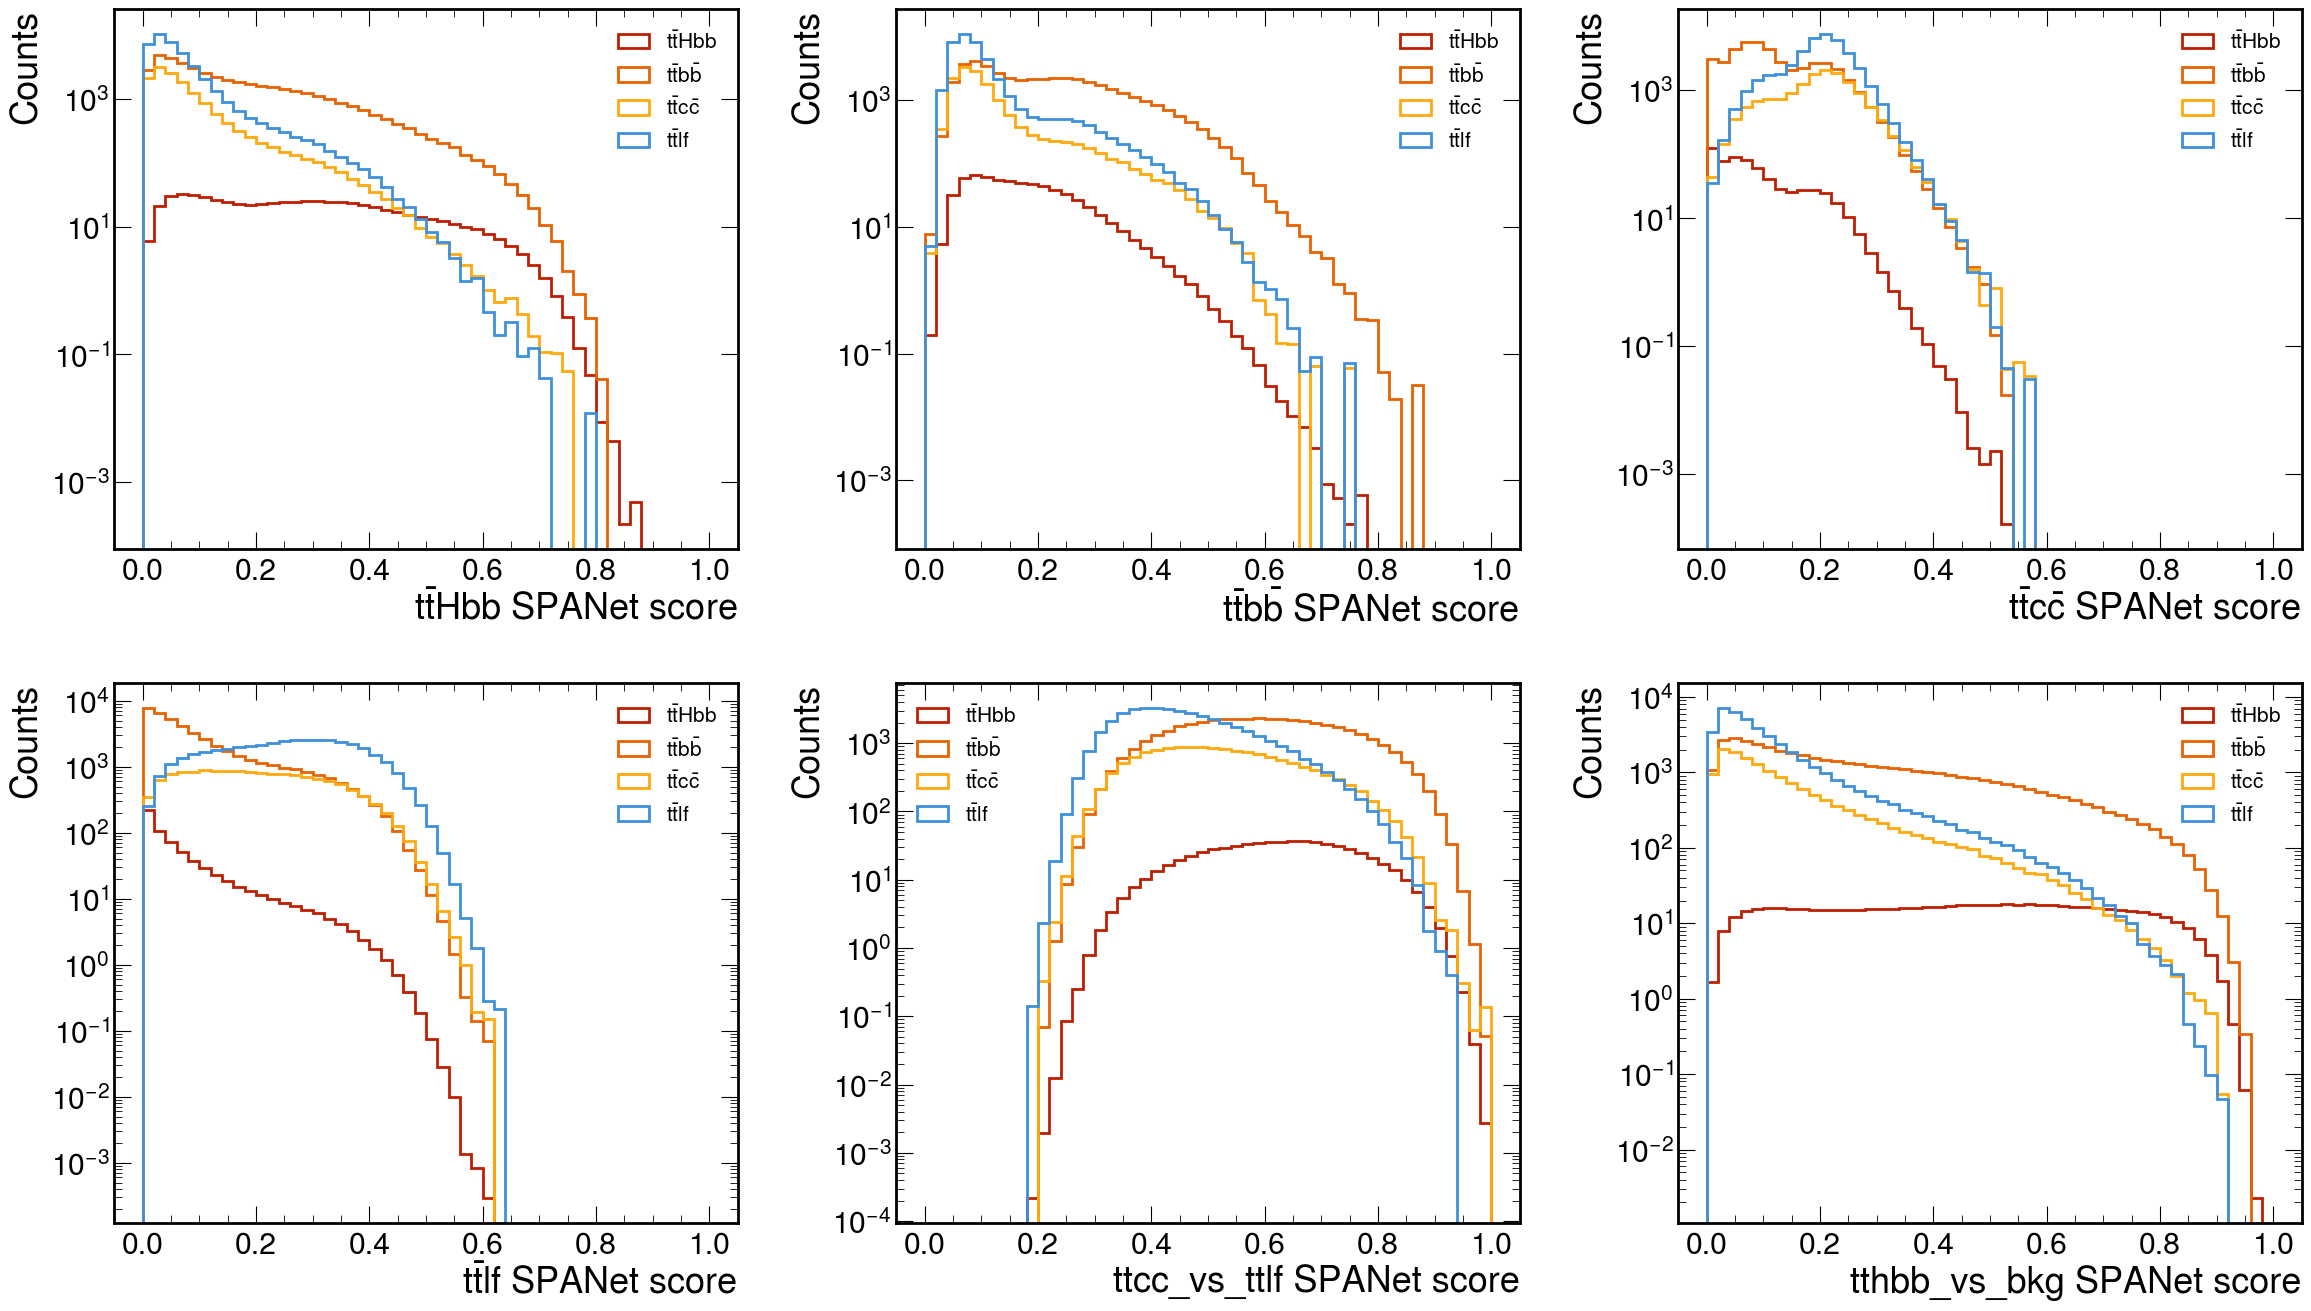

In [33]:
plot_scores(true_labels, pred_labels_new, plot_dir=save_folder, weights=event_weights, log=True, density=False)

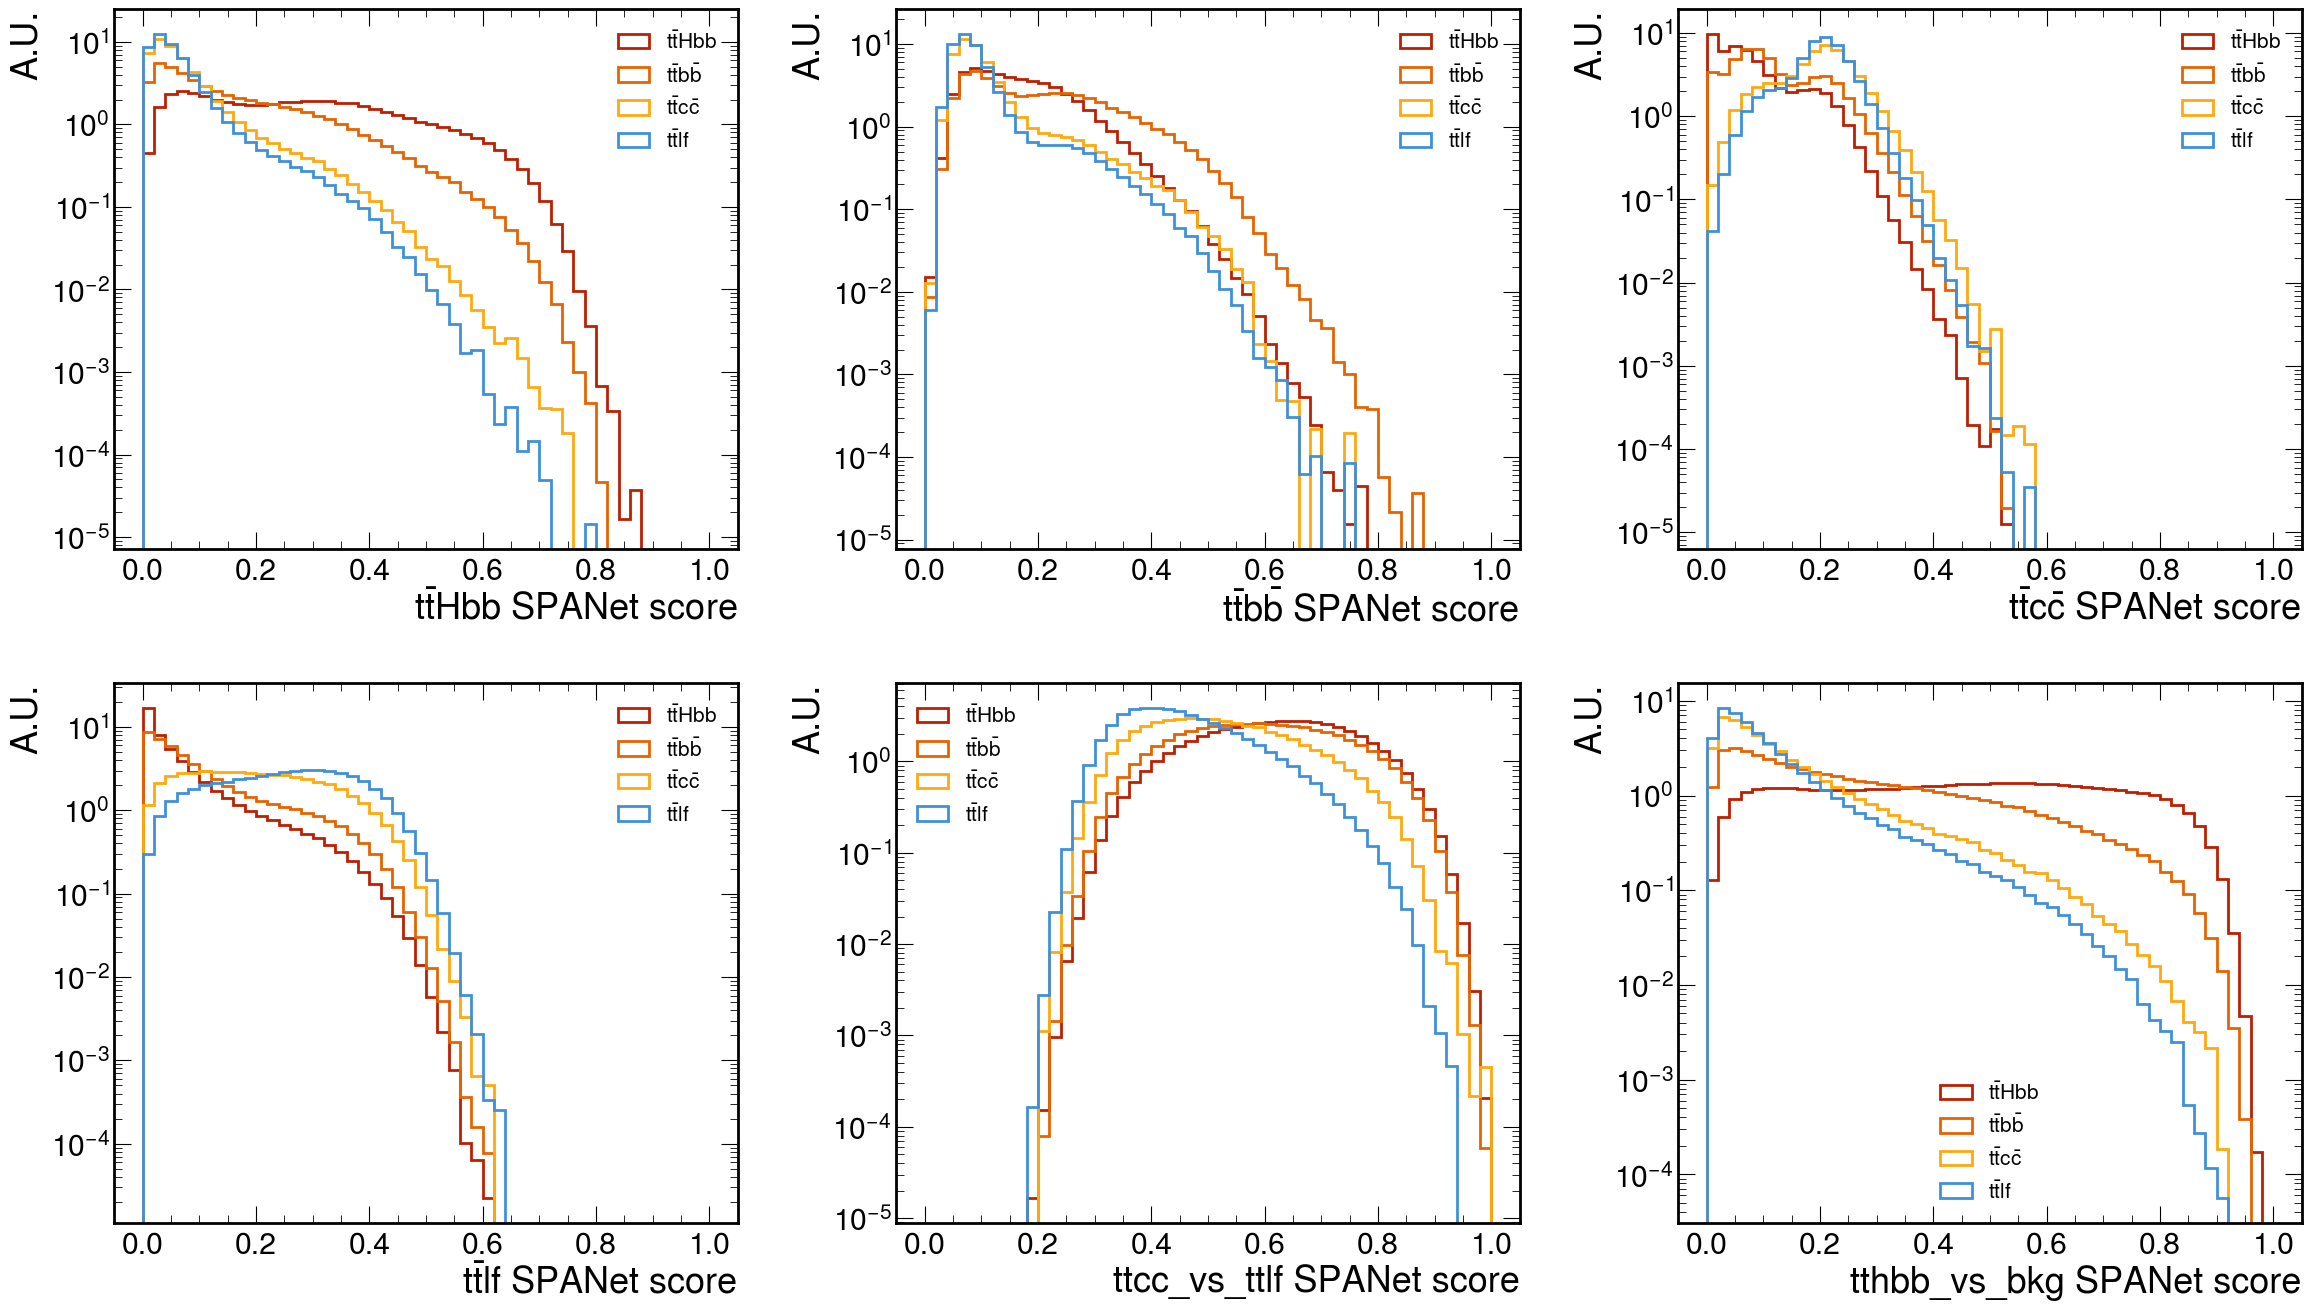

In [34]:
plot_scores(true_labels, pred_labels_new, plot_dir=save_folder, weights=event_weights, log=True, density=True)

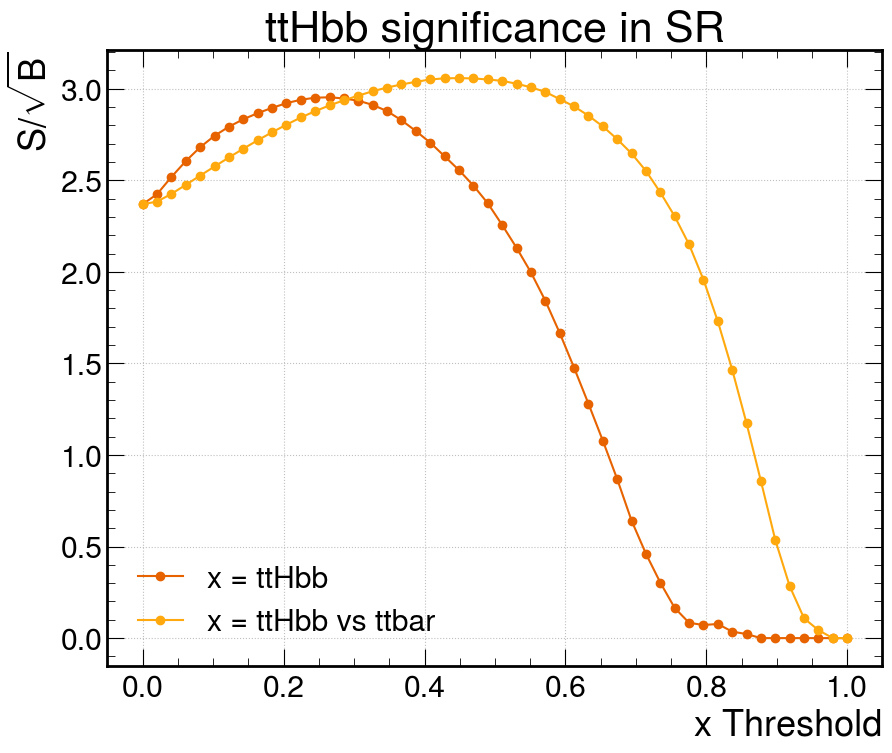

In [41]:
# scan different thresholds for the tthbb_wp and plot the cumulative significance for the ttHbb SR and the ttbb CR as a function of the tthbb_wp threshold, while keeping the ttlf_low and ttcc_high fixed to the values defined above
ttlf_low = 0.2
ttlf_high = 0.4

# save true scores for signal and background
true_signal = true_labels["tthbb"]
true_bkg = ~true_signal
pred_signal = pred_labels_new["tthbb"]
thresholds = np.linspace(0.0, 1, 50)
significances_sr = []
significances_sr_2 = []
significances_sr_3 = []
for tthbb_wp in thresholds:
    sr2_tthbb = (pred_labels_new["ttlf"] < ttlf_low) & (pred_labels_new["tthbb"] > tthbb_wp)
    sr3_tthbb = (pred_labels_new["ttlf"] < ttlf_low) & (pred_labels_new["tthbb_vs_bkg"] > tthbb_wp)
    
    # calculate significance for SR and CR using the true labels and the region definitions
    s_sr_2 = np.sum(event_weights[true_signal & sr2_tthbb])
    b_sr_2 = np.sum(event_weights[true_bkg & sr2_tthbb])
    significance_sr_2 = s_sr_2 / np.sqrt(s_sr_2 + b_sr_2) if (s_sr_2 + b_sr_2) > 0 else 0.0
    significances_sr_2.append(significance_sr_2)
    
    s_sr_3 = np.sum(event_weights[true_signal & sr3_tthbb])
    b_sr_3 = np.sum(event_weights[true_bkg & sr3_tthbb])
    significance_sr_3 = s_sr_3 / np.sqrt(s_sr_3 + b_sr_3) if (s_sr_3 + b_sr_3) > 0 else 0.0
    significances_sr_3.append(significance_sr_3)

fig, ax1 = plt.subplots(figsize=[10,8])
ax1.plot(thresholds, significances_sr_2, marker='o', linestyle='-', color=colors["ttbb"], label="x = ttHbb")
ax1.plot(thresholds, significances_sr_3, marker='o', linestyle='-', color=colors["ttcc"], label="x = ttHbb vs ttbar")
ax1.set_xlabel("x Threshold")
ax1.set_ylabel("S/$\sqrt{B}$ ")
ax1.set_title("ttHbb significance in SR")
ax1.grid(True)
ax1.legend()
fig.savefig(os.path.join(save_folder, f"significance_tthbb_wp.png"), dpi=300)
plt.show()

# ttHbb SR with ttHbb_vs_bkg cut

In [35]:
low_score = 0.10
high_score = 1.0
ttlf_low = 0.2
score_thr = np.round(np.arange(low_score, high_score, 0.02), 2)

non_ttlf_cr  = (pred_labels_new["ttlf"] < ttlf_low)
masks_for_cr_sr = {}
scores = ["tthbb", "ttbb","ttcc","ttlf","ttcc_vs_ttlf", "tthbb_vs_bkg"]
for score in scores:
    masks_for_cr_sr[score] = {}
    for sample in labels:
        masks_for_cr_sr[score][sample] = {}
        for thr in score_thr:
            masks_for_cr_sr[score][sample][thr] = (pred_labels_new[score] > thr) & true_labels[sample] & non_ttlf_cr 

In [36]:
purity = {}
efficiency = {}
sample_denominators = {sample: np.sum(true_labels[sample] * event_weights) for sample in labels}

for score in scores:
    purity[score] = {}
    efficiency[score] = {}
    purity_denominators = {}
    for thr in score_thr:
        total_weighted_sum = 0.0
        for s in labels:
            total_weighted_sum += np.sum(masks_for_cr_sr[score][s][thr] * event_weights)
        purity_denominators[thr] = total_weighted_sum

    for sample in labels:
        purity[score][sample] = {}
        efficiency[score][sample] = {}
        
        den_eff = sample_denominators[sample]
        
        for thr in score_thr:
            num = np.sum(masks_for_cr_sr[score][sample][thr] * event_weights)
            den_pur = purity_denominators[thr]
            purity[score][sample][thr] = num / den_pur if den_pur > 0 else 0.0
            efficiency[score][sample][thr] = num / den_eff if den_eff > 0 else 0.0

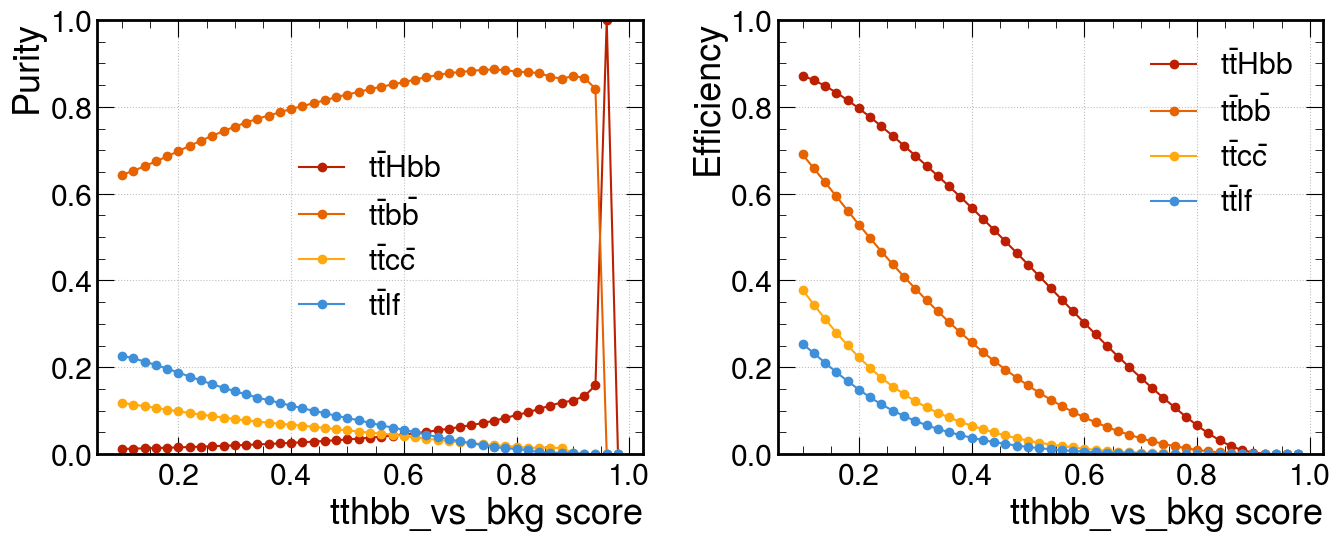

In [38]:
# plot the purity and efficiency for tthbb_vs_bkg
score_to_plot = "tthbb_vs_bkg"
thr_vals = np.array(score_thr)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=[14,6])
for sample in labels_to_plot.keys():
    ax1.plot(thr_vals, [purity[score_to_plot][sample][thr] for thr in thr_vals], marker='o', linestyle='-', color=colors[sample], label=labels_legend.get(sample, sample))
    ax2.plot(thr_vals, [efficiency[score_to_plot][sample][thr] for thr in thr_vals], marker='o', linestyle='-', color=colors[sample], label=labels_legend.get(sample, sample))

ax1.set_xlabel(f"{score_to_plot} score")
ax1.set_ylabel("Purity")
ax1.set_ylim(0, 1)
ax1.grid(True)
ax1.legend()
ax2.set_xlabel(f"{score_to_plot} score")
ax2.set_ylabel("Efficiency")
ax2.set_ylim(0, 1)
ax2.grid(True)
ax2.legend()
fig.tight_layout()
fig.savefig(os.path.join(save_folder, f"purity_efficiency_{score_to_plot}.png"), dpi=300)

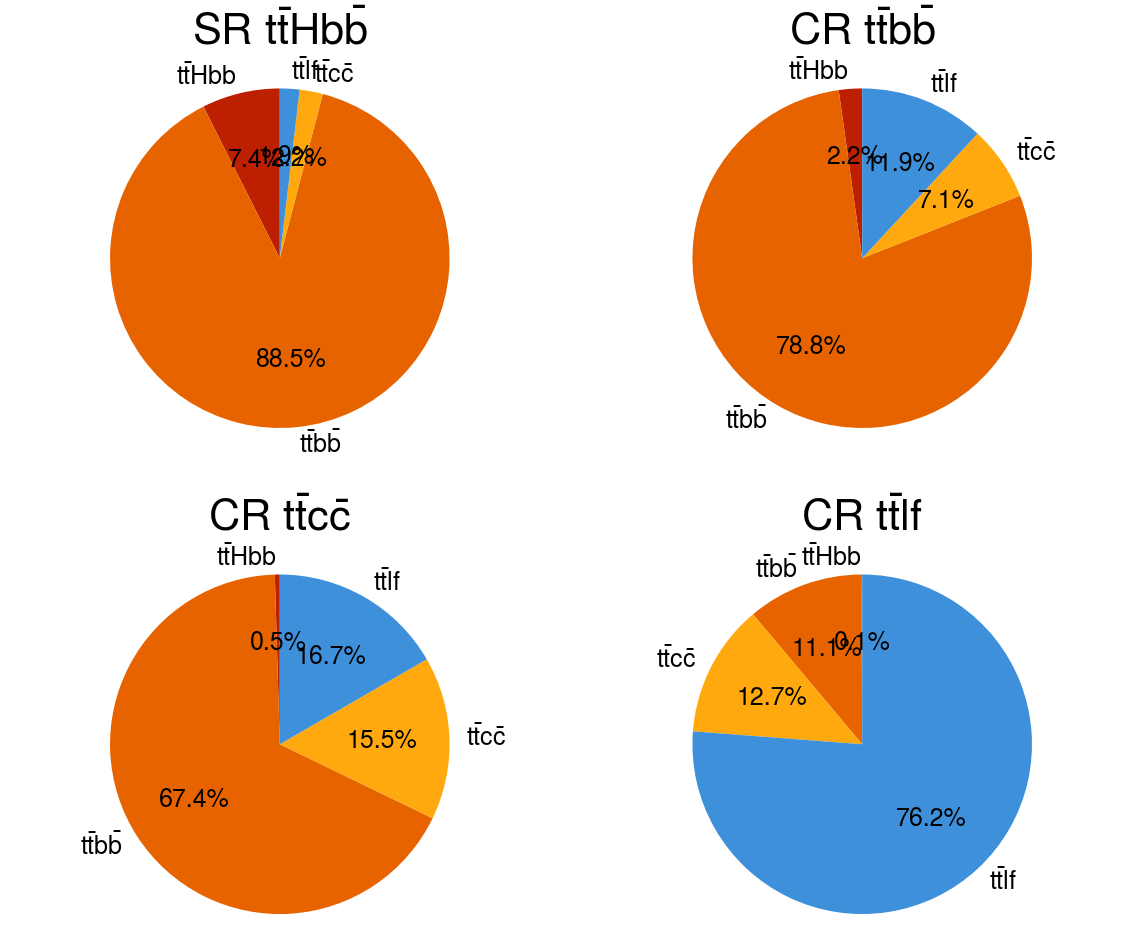

In [56]:
ttlf_low = 0.2
ttlf_high = 0.4
tthbb_low = 0.4
tthbb_high = 0.75
ttcc_high = 0.65

cr_ttlf  = (pred_labels_new["ttlf"] > ttlf_high)
sr_tthbb = (pred_labels_new["ttlf"] < ttlf_low) & (pred_labels_new["tthbb_vs_bkg"] > tthbb_high)
cr_ttbb  = (pred_labels_new["ttlf"] < ttlf_low) & (pred_labels_new["tthbb_vs_bkg"] < tthbb_high) & (pred_labels_new["tthbb_vs_bkg"] > tthbb_low)
cr_ttcc  = (pred_labels_new["ttlf"] < ttlf_low) & (pred_labels_new["tthbb_vs_bkg"] < tthbb_low)  & (pred_labels_new["ttcc_vs_ttlf"] > ttcc_high)

cr_definitions = {
    r"SR $t\bar{t}Hb\bar{b}$": sr_tthbb,
    r"CR $t\bar{t}b\bar{b}$": cr_ttbb,
    r"CR $t\bar{t}c\bar{c}$": cr_ttcc,
    r"CR $t\bar{t}$lf": cr_ttlf
}

# make a pie chart for each control region with the fraction of events from each class
# relative to the total number of events in that region
fig, axs = plt.subplots(2, 2, figsize=[12, 10], dpi=100)
axs = axs.flatten()

for i, (region_name, region_mask) in enumerate(cr_definitions.items()):
    ax = axs[i]

    sample_counts = []
    sample_labels = []
    sample_colors = []

    for sample_key in labels_to_plot.keys():
        mask_by_sample = np.asarray(true_labels[sample_key], dtype=bool)
        count = np.sum(event_weights[mask_by_sample & region_mask])
        if count > 0:
            sample_counts.append(count)
            sample_labels.append(labels_legend.get(sample_key, sample_key))
            sample_colors.append(colors.get(sample_key))

    total_region_events = np.sum(sample_counts)

    if total_region_events > 0:
        ax.pie(
            sample_counts,
            labels=sample_labels,
            autopct=lambda pct: f"{pct:.1f}%",
            startangle=90,
            colors=sample_colors,
            textprops={'fontsize': 18},
        )
        ax.set_title(f"{region_name}", pad=20)
    else:
        ax.text(0.5, 0.5, 'No events', horizontalalignment='center', verticalalignment='center')
        ax.set_title(f"{region_name}")

    ax.axis('equal')  # Equal aspect ratio ensures that pie chart is circular.

cut_str = str(tthbb_high).replace(".", "p")
fig.tight_layout()
fig.savefig(os.path.join(save_folder, f"control_regions_tthbb_vs_all_cut_weighted_{cut_str}.png"), dpi=300)
plt.show()

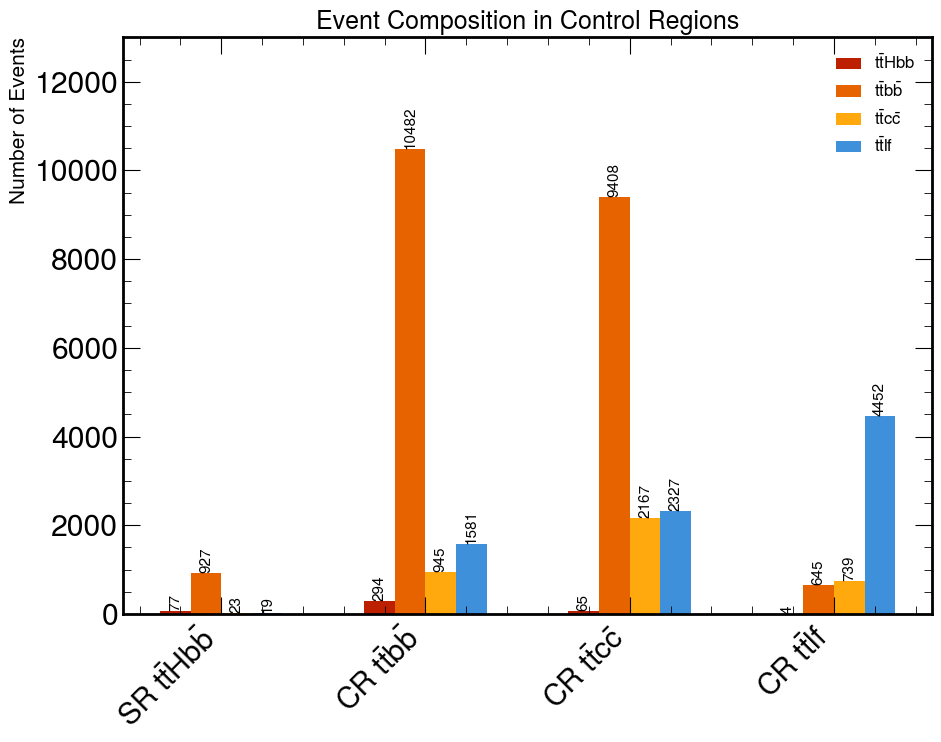

In [51]:
# bar histogram with the number of events from each class in each control region
fig, ax = plt.subplots(figsize=[10, 8], dpi=100)
region_names = list(cr_definitions.keys())
bar_width = 0.15
index = np.arange(len(region_names))
for i, sample_key in enumerate(labels_to_plot.keys()):
    counts = []
    for region_mask in cr_definitions.values():
        mask_by_sample = np.asarray(true_labels[sample_key], dtype=bool)
        count = np.sum(event_weights[mask_by_sample & region_mask])
        counts.append(count)
    bars = ax.bar(
        index + i * bar_width,
        counts,
        bar_width,
        label=labels_legend.get(sample_key, sample_key),
        color=colors.get(sample_key),
    )

    for bar, count in zip(bars, counts):
        if count > 0:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height(),
                f"{int(count)}",
                ha='center',
                va='bottom',
                fontsize=11,
                rotation=90,
            )
cut_str = str(tthbb_high).replace(".", "p")
#ax.set_xlabel('Control Regions', fontsize=15)
ax.set_ylabel('Number of Events', fontsize=15)
ax.set_title('Event Composition in Control Regions', fontsize=18)
ax.set_xticks(index + bar_width * (len(labels_to_plot) - 1) / 2)
ax.set_xticklabels(region_names, rotation=45, ha='right')
ax.legend(fontsize=12)
ax.set_ylim(0, 13000)
fig.tight_layout()
fig.savefig(os.path.join(save_folder, f"control_regions_tthbb_vs_all_cut_{cut_str}_bar.png"), dpi=300)
plt.show()

In [57]:
# ttHbb signal efficiency and S/sqrt(B) in the SR (tthbb_vs_bkg cut)
is_tthbb = true_labels["tthbb"]
w = ak.to_numpy(event_weights)
n_tthbb_tot = np.sum(w[is_tthbb])
n_tthbb_sr = np.sum(w[is_tthbb & sr_tthbb])
eff_tthbb_sr = n_tthbb_sr / n_tthbb_tot if n_tthbb_tot > 0 else 0.0
eff_tthbb_sr_unw = np.sum(is_tthbb & sr_tthbb) / np.sum(is_tthbb)

# background = all non-ttHbb events in the SR
s_sr = n_tthbb_sr
b_sr = np.sum(w[~is_tthbb & sr_tthbb])
s_over_sqrt_b = s_sr / np.sqrt(b_sr) if b_sr > 0 else 0.0

print(f"SR cuts: ttlf < {ttlf_low}, tthbb_vs_bkg > {tthbb_high}")
print(f"ttHbb weighted yield: total = {n_tthbb_tot:.2f}, in SR = {n_tthbb_sr:.2f}")
print(f"ttHbb signal efficiency in SR (weighted):   {eff_tthbb_sr:.4f}")
print(f"ttHbb signal efficiency in SR (unweighted): {eff_tthbb_sr_unw:.4f}")
print(f"SR yields: S = {s_sr:.2f}, B = {b_sr:.2f}")
print(f"S/sqrt(B) in SR: {s_over_sqrt_b:.4f}")

SR cuts: ttlf < 0.2, tthbb_vs_bkg > 0.75
ttHbb weighted yield: total = 655.71, in SR = 77.79
ttHbb signal efficiency in SR (weighted):   0.1186
ttHbb signal efficiency in SR (unweighted): 0.1315
SR yields: S = 77.79, B = 1028.30
S/sqrt(B) in SR: 2.4260


In [92]:
non_ttbb_cr  = (pred_labels_new["ttlf"] < ttlf_low) & (pred_labels_new["tthbb_vs_bkg"] < tthbb_low)
masks_for_ttcc_cr = {}
scores = ["tthbb", "ttbb","ttcc","ttlf","ttcc_vs_ttlf", "tthbb_vs_ttbb","tthbb_vs_bkg"]
for score in scores:
    masks_for_ttcc_cr[score] = {}
    for sample in labels:
        masks_for_ttcc_cr[score][sample] = {}
        for thr in score_thr:
            masks_for_ttcc_cr[score][sample][thr] = (pred_labels_new[score] > thr) & true_labels[sample] & non_ttbb_cr 

In [93]:
purity = {}
efficiency = {}
sample_denominators = {sample: np.sum(true_labels[sample] * event_weights) for sample in labels}

for score in scores:
    purity[score] = {}
    efficiency[score] = {}
    purity_denominators = {}
    for thr in score_thr:
        total_weighted_sum = 0.0
        for s in labels:
            total_weighted_sum += np.sum(masks_for_ttcc_cr[score][s][thr] * event_weights)
        purity_denominators[thr] = total_weighted_sum

    for sample in labels:
        purity[score][sample] = {}
        efficiency[score][sample] = {}
        
        den_eff = sample_denominators[sample]
        
        for thr in score_thr:
            num = np.sum(masks_for_ttcc_cr[score][sample][thr] * event_weights)
            den_pur = purity_denominators[thr]
            purity[score][sample][thr] = num / den_pur if den_pur > 0 else 0.0
            efficiency[score][sample][thr] = num / den_eff if den_eff > 0 else 0.0

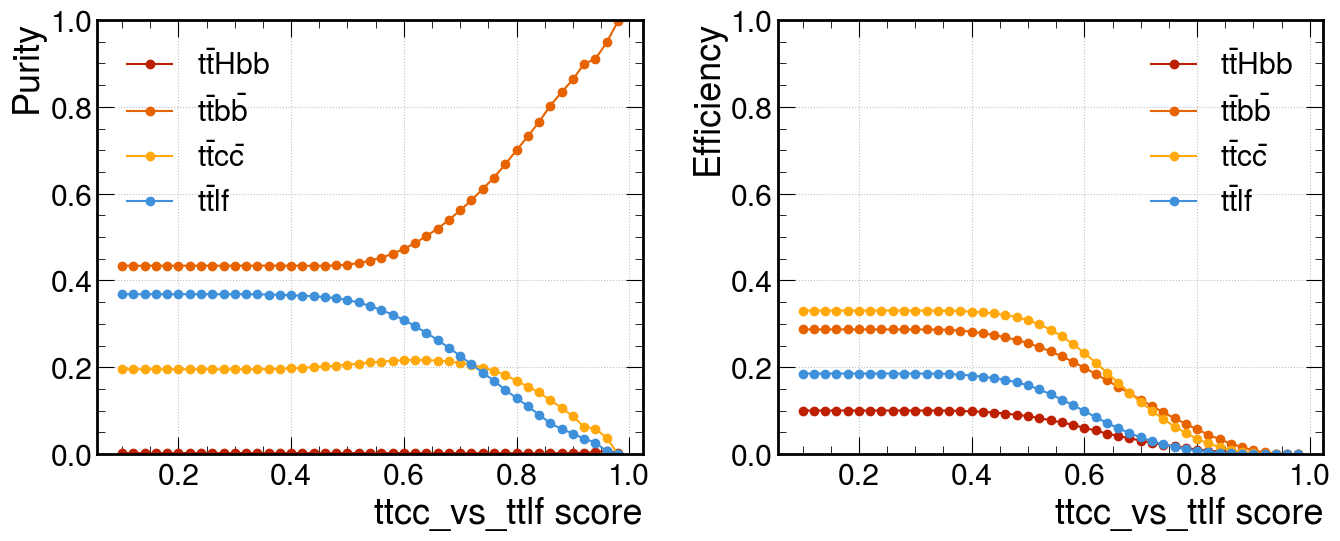

In [94]:
# plot the purity and efficiency for tthbb_vs_bkg
score_to_plot = "ttcc_vs_ttlf"
thr_vals = np.array(score_thr)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=[14,6])
for sample in labels_to_plot.keys():
    ax1.plot(thr_vals, [purity[score_to_plot][sample][thr] for thr in thr_vals], marker='o', linestyle='-', color=colors[sample], label=labels_legend.get(sample, sample))
    ax2.plot(thr_vals, [efficiency[score_to_plot][sample][thr] for thr in thr_vals], marker='o', linestyle='-', color=colors[sample], label=labels_legend.get(sample, sample))

ax1.set_xlabel(f"{score_to_plot} score")
ax1.set_ylabel("Purity")
ax1.set_ylim(0, 1)
ax1.grid(True)
ax1.legend()
ax2.set_xlabel(f"{score_to_plot} score")
ax2.set_ylabel("Efficiency")
ax2.set_ylim(0, 1)
ax2.grid(True)
ax2.legend()
fig.tight_layout()
fig.savefig(os.path.join(save_folder, f"purity_efficiency_{score_to_plot}.png"), dpi=300)